In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from src.features import make_features

FEATS = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]
UNSEEN_SITES = ["Panther", "Swan"]
MAX_MISSING = 0.20          # the same quality rule as notebook 01

df_clean = pd.read_parquet("../data/processed/electricity_clean.parquet")
temp = pd.read_parquet("../data/processed/air_temperature.parquet")
train_buildings = pd.read_csv("../configs/train_buildings.csv")["building"].tolist()
print("df_clean:", df_clean.shape, "index type:", type(df_clean.index).__name__)

# Buildings of the unseen sites: same rule (at most 20% missing), checked on 2017 only
candidates = [b for b in df_clean.columns if b.split("_")[0] in UNSEEN_SITES]
missing_2017 = df_clean.loc[df_clean.index.year == 2017, candidates].isna().mean()
unseen_buildings = missing_2017[missing_2017 <= MAX_MISSING].index.tolist()
print(len(candidates), "buildings on Panther/Swan,", len(unseen_buildings), "pass the 20% rule in 2017")
print(pd.Series([b.split("_")[0] for b in unseen_buildings]).value_counts().to_string())


def build(buildings):
    parts = []
    for b in buildings:
        f = make_features(b, df_clean, temp)
        num = f.columns.drop("building")
        f[num] = f[num].astype("float32")
        parts.append(f)
    out = pd.concat(parts)
    out["building"] = out["building"].astype("category")
    return out


data = build(train_buildings)                      # the 1,083 training buildings, 2016 + 2017
unseen = build(unseen_buildings)
unseen = unseen[unseen.index.year == 2017]         # unseen sites: 2017 only, never trained on
print(len(data), "rows for known buildings,", len(unseen), "rows for unseen buildings")
print("temperature range:", float(data["temp"].min()), "to", float(data["temp"].max()), "(should be °C)")

df_clean: (17544, 1578) index type: DatetimeIndex
124 buildings on Panther/Swan, 124 pass the 20% rule in 2017
Panther    105
Swan        19
19000152 rows for known buildings, 1086240 rows for unseen buildings
temperature range: -28.899999618530273 to 48.29999923706055 (should be °C)


                    buildings  win_pct  median_improvement_pct  median_rel_mae
group                                                                         
known sites              1083   77.932                  11.271           0.097
unseen: Panther           105   53.333                   2.367           0.092
unseen: Swan               19   89.474                  14.674           0.064
unseen: both sites        124   58.871                   3.984           0.091


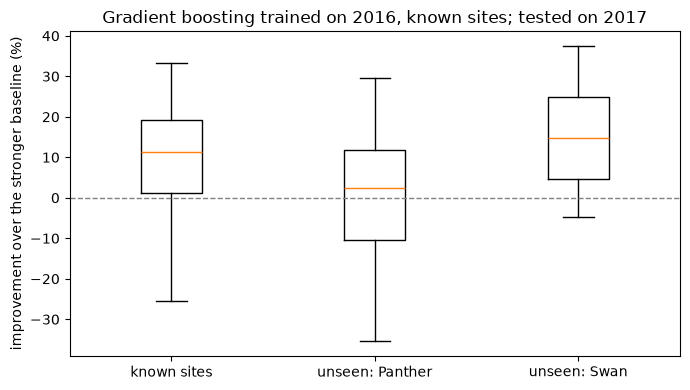

In [2]:
train = data[data.index.year == 2016].dropna(subset=["load_n"])
gbm = HistGradientBoostingRegressor(random_state=0).fit(train[FEATS], train["load_n"])
del train


def score(df, group):
    """Per-building MAE (kWh) of the model and of both baselines, on the same rows."""
    d = df.dropna(subset=["load", "lag24", "lag168", "scale"])
    pred = gbm.predict(d[FEATS]) * d["scale"].to_numpy()
    load = d["load"].to_numpy()
    err = pd.DataFrame({
        "building": d["building"].astype(str).to_numpy(),
        "mae_model": np.abs(load - pred),
        "mae_yesterday": np.abs(load - d["lag24"].to_numpy()),
        "mae_lastweek": np.abs(load - d["lag168"].to_numpy()),
        "mean_load": load,
    })
    res = err.groupby("building").mean()
    res["best_baseline"] = res[["mae_yesterday", "mae_lastweek"]].min(axis=1)
    res["wins"] = res["mae_model"] < res["best_baseline"]
    res["improvement"] = 1 - res["mae_model"] / res["best_baseline"]
    res["rel_mae"] = res["mae_model"] / res["mean_load"]
    res["site"] = res.index.str.split("_").str[0]
    res["group"] = group
    return res


known = score(data[data.index.year == 2017], "known sites")
new = score(unseen, "unseen sites")
new["group"] = "unseen: " + new["site"]
both = pd.concat([known, new])

summary = both.groupby("group").agg(
    buildings=("wins", "size"),
    win_pct=("wins", lambda s: 100 * s.mean()),
    median_improvement_pct=("improvement", lambda s: 100 * s.median()),
    median_rel_mae=("rel_mae", "median"))
summary.loc["unseen: both sites"] = [len(new), 100 * new["wins"].mean(),
                                     100 * new["improvement"].median(), new["rel_mae"].median()]
summary["buildings"] = summary["buildings"].astype(int)
print(summary.round(3).to_string())

known.to_csv("../results/tables/cv_known_2017.csv")
new.to_csv("../results/tables/cv_unseen_sites.csv")
summary.to_csv("../results/tables/cv_unseen_summary.csv")

order = ["known sites"] + sorted(new["group"].unique())
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([100 * both.loc[both["group"] == g, "improvement"].clip(-1, 1) for g in order],
           showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order)
ax.axhline(0, color="grey", lw=1, ls="--")
ax.set_ylabel("improvement over the stronger baseline (%)")
ax.set_title("Gradient boosting trained on 2016, known sites; tested on 2017")
plt.tight_layout()
plt.savefig("../results/figures/cv_unseen_sites.png", dpi=150)
plt.show()

In [3]:
LEVEL, GAMMA = 0.90, 0.05
alpha = 1 - LEVEL
year, month = data.index.year, data.index.month
fit = data[(year == 2016) & (month <= 10)].dropna(subset=["load_n"])
cal = data[(year == 2016) & (month >= 11)].dropna(subset=["load_n"])

q_lo = HistGradientBoostingRegressor(loss="quantile", quantile=alpha / 2, random_state=0).fit(fit[FEATS], fit["load_n"])
q_hi = HistGradientBoostingRegressor(loss="quantile", quantile=1 - alpha / 2, random_state=0).fit(fit[FEATS], fit["load_n"])
del fit


def conformal_q(s_sorted, a):
    """The ceil((n+1)(1-a))-th smallest score, capped to the scores we have (as in M2)."""
    n = len(s_sorted)
    k = int(np.ceil((n + 1) * (1 - a)))
    return s_sorted[min(max(k, 1), n) - 1]


# CQR scores on the known sites' calibration months: how far outside the interval each value is
y_cal = cal["load_n"].to_numpy()
scores = np.sort(np.maximum(q_lo.predict(cal[FEATS]) - y_cal, y_cal - q_hi.predict(cal[FEATS])))
q_cqr = conformal_q(scores, alpha)
print("global CQR correction:", round(float(q_cqr), 4))
del cal


def intervals(df):
    d = df.dropna(subset=["load_n"])
    return d, q_lo.predict(d[FEATS]), q_hi.predict(d[FEATS])


def aci(d, lo_t, hi_t):
    """ACI per building, one update per day, starting from the global calibration scores."""
    y = d["load_n"].to_numpy()
    days = d.index.normalize().to_numpy()
    lo, hi = np.empty(len(d)), np.empty(len(d))
    for b, rows in d.groupby("building", observed=True).indices.items():
        _, starts = np.unique(days[rows], return_index=True)
        bounds = list(starts) + [len(rows)]
        a = alpha
        for k in range(len(starts)):
            idx = rows[bounds[k]:bounds[k + 1]]
            q = conformal_q(scores, min(max(a, 1e-6), 1))
            lo[idx], hi[idx] = lo_t[idx] - q, hi_t[idx] + q
            miss = 1 - ((y[idx] >= lo[idx]) & (y[idx] <= hi[idx])).mean()
            a += GAMMA * (alpha - miss)
    return lo, hi


rows = []
for name, df in [("known sites", data[year == 2017]), ("unseen sites", unseen)]:
    d, lo_t, hi_t = intervals(df)
    y = d["load_n"].to_numpy()
    site = d["building"].astype(str).str.split("_").str[0].to_numpy()
    for method, (lo, hi) in {"CQR (global)": (lo_t - q_cqr, hi_t + q_cqr),
                             "ACI on CQR": aci(d, lo_t, hi_t)}.items():
        covered = pd.Series((y >= lo) & (y <= hi), index=d["building"].astype(str).to_numpy())
        per_b = covered.groupby(level=0).mean()
        groups = {name: np.ones(len(y), bool)}
        if name == "unseen sites":
            groups.update({"unseen: " + s: site == s for s in UNSEEN_SITES})
        for g, m in groups.items():
            pb = covered[m].groupby(level=0).mean()
            rows.append({"group": g, "method": method, "coverage": covered[m].mean(),
                         "rel_width": np.mean((hi - lo)[m]),
                         "buildings": len(pb), "below_80pct": int((pb < 0.8).sum()),
                         "worst_building": pb.min()})
cov_table = pd.DataFrame(rows)
print(cov_table.round(3).to_string(index=False))
cov_table.to_csv("../results/tables/cv_unseen_coverage.csv", index=False)

global CQR correction: 0.0035
          group       method  coverage  rel_width  buildings  below_80pct  worst_building
    known sites CQR (global)     0.898      0.474       1083          116           0.608
    known sites   ACI on CQR     0.901      1.035       1083            0           0.890
   unseen sites CQR (global)     0.908      0.476        124           10           0.677
unseen: Panther CQR (global)     0.900      0.485        105           10           0.677
   unseen: Swan CQR (global)     0.955      0.423         19            0           0.852
   unseen sites   ACI on CQR     0.902      0.726        124            0           0.894
unseen: Panther   ACI on CQR     0.901      0.790        105            0           0.894
   unseen: Swan   ACI on CQR     0.906      0.356         19            0           0.898


coverage columns: ['Split conformal', 'Quantile GBM', 'CQR', 'CQR per building', 'ACI']
using: CQR per building and ACI
0 buildings without metadata, 0 without M2 coverage
                               buildings  win_pct  median_improvement_pct  median_rel_mae  cqr_b_below_80  median_cov_cqr_b  median_cov_aci  median_sqm
type                                                                                                                                                   
Education                          412.0   87.136                  16.793           0.086            16.0             0.899           0.900     8044.45
Office                             213.0   88.732                  15.517           0.094             0.0             0.907           0.900     5737.30
Public services                    130.0   70.000                   5.172           0.121             3.0             0.900           0.900     2043.90
Entertainment/public assembly      125.0   72.800                   

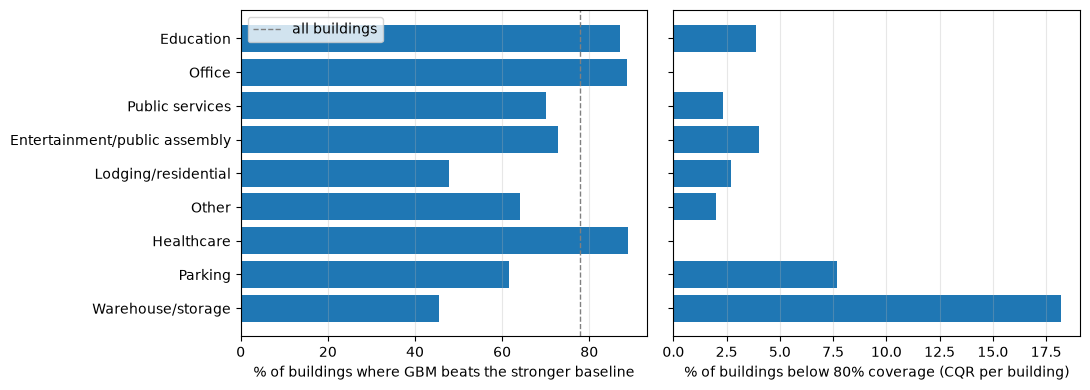

In [4]:
meta = pd.read_csv("../data/raw/metadata.csv").set_index("building_id")
cov90 = pd.read_csv("../results/tables/m2_coverage_per_building_90.csv", index_col=0)
print("coverage columns:", list(cov90.columns))

# Pick the two M2 methods by name, so small differences in the column names don't matter
col_cqr_b = [c for c in cov90.columns if "per building" in c.lower() and "aci" not in c.lower()][0]
col_aci = [c for c in cov90.columns if "aci" in c.lower()][0]
print("using:", col_cqr_b, "and", col_aci)

tab = known.join(meta[["primaryspaceusage", "sqm"]], how="left")
tab = tab.join(cov90[[col_cqr_b, col_aci]].rename(columns={col_cqr_b: "cov_cqr_b", col_aci: "cov_aci"}), how="left")
print(tab["primaryspaceusage"].isna().sum(), "buildings without metadata,",
      tab["cov_cqr_b"].isna().sum(), "without M2 coverage")

# Rare types (fewer than 10 buildings) go into "Other", so no group is 2 or 3 buildings
tab["type"] = tab["primaryspaceusage"].fillna("Unknown")
counts = tab["type"].value_counts()
tab.loc[tab["type"].isin(counts[counts < 10].index), "type"] = "Other"


def describe(g):
    return pd.Series({
        "buildings": len(g),
        "win_pct": 100 * g["wins"].mean(),
        "median_improvement_pct": 100 * g["improvement"].median(),
        "median_rel_mae": g["rel_mae"].median(),
        "cqr_b_below_80": int((g["cov_cqr_b"] < 0.8).sum()),
        "median_cov_cqr_b": g["cov_cqr_b"].median(),
        "median_cov_aci": g["cov_aci"].median(),
        "median_sqm": g["sqm"].median(),
    })


COLS = ["wins", "improvement", "rel_mae", "cov_cqr_b", "cov_aci", "sqm"]
by_type = tab.groupby("type")[COLS].apply(describe).sort_values("buildings", ascending=False)
print(by_type.round(3).to_string())

# Size: 4 equal groups of buildings by floor area
tab["size_group"] = pd.qcut(tab["sqm"], 4, labels=["smallest 25%", "25-50%", "50-75%", "largest 25%"])
by_size = tab.groupby("size_group", observed=True)[COLS].apply(describe)
print(by_size.round(3).to_string())

by_type.to_csv("../results/tables/cv_by_building_type.csv")
by_size.to_csv("../results/tables/cv_by_building_size.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
names = by_type.index[::-1]
axes[0].barh(names, by_type.loc[names, "win_pct"])
axes[0].axvline(100 * tab["wins"].mean(), color="grey", ls="--", lw=1, label="all buildings")
axes[0].set_xlabel("% of buildings where GBM beats the stronger baseline")
axes[0].legend()
axes[1].barh(names, 100 * by_type.loc[names, "cqr_b_below_80"] / by_type.loc[names, "buildings"])
axes[1].set_xlabel("% of buildings below 80% coverage (CQR per building)")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/figures/cv_by_building_type.png", dpi=150)
plt.show()

1083 buildings pass the rule here; 1083 in configs/train_buildings.csv; 0 differ
    site  year  buildings  used  median_missing_pct  flat_hours  both_lags_missing_h  temp_missing_pct  temp_longest_gap_h  temp_missing_after_fill_pct  dew_above_temp_h  temp_outside_-40_50_h  max_jump_C_per_h
    Bear  2016         92    81                0.05         794                 3368              0.01                   1                         0.00                 0                      0              10.0
    Bear  2017         92    81                0.43        1779                  978              0.01                   1                         0.00                 0                      0               7.8
  Bobcat  2016         35    13                2.52           0                 1312              0.30                  11                         0.00                 0                      0               9.5
  Bobcat  2017         35    13               24.04           0            

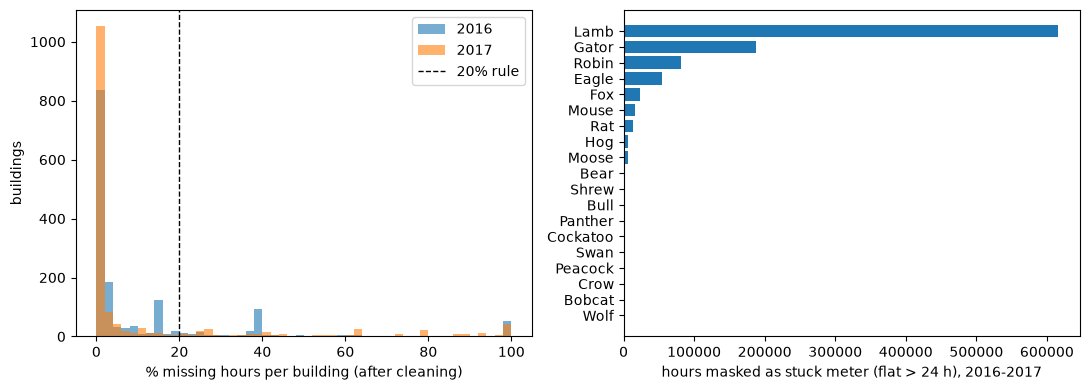

In [5]:
raw = pd.read_csv("../data/raw/electricity_cleaned.csv", index_col="timestamp", parse_dates=True)
raw = raw.asfreq("h")                              # every hour present, missing hours become NaN
train_set, unseen_set = set(train_buildings), set(unseen_buildings)


def run_lengths(mask):
    """Start position and length of every run of True values in a boolean array."""
    m = np.concatenate([[False], mask, [False]]).astype(int)
    d = np.diff(m)
    starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
    return starts, ends - starts


def flat_mask(v, max_len=24):
    """True for hours inside a run of identical values longer than max_len hours."""
    same = np.zeros(len(v), bool)
    same[1:] = v[1:] == v[:-1]                     # NaN == NaN is False, so gaps break runs
    starts, lengths = run_lengths(same)            # runs of "equal to the previous hour"
    out = np.zeros(len(v), bool)
    n_runs = 0
    for s, L in zip(starts, lengths):
        if L + 1 > max_len:                        # L repeats = L + 1 identical hours
            out[s - 1:s + L] = True
            n_runs += 1
    return out, n_runs


years = raw.index.year.to_numpy()
rows = []
for b in raw.columns:
    v = raw[b].to_numpy(dtype=float)
    flat, _ = flat_mask(v)
    v_clean = np.where(flat, np.nan, v)
    status = "train" if b in train_set else "unseen test" if b in unseen_set else "not used"
    for yr in (2016, 2017):
        m = years == yr
        miss_raw, miss_clean = np.isnan(v[m]), np.isnan(v_clean[m])
        _, gaps = run_lengths(miss_clean)
        _, n_flat = flat_mask(v[m])
        row = {"building": b, "site": b.split("_")[0], "year": yr, "status": status,
               "missing_raw_pct": 100 * miss_raw.mean(),
               "flat_runs": n_flat,
               "flat_hours": int(flat[m].sum()),
               "missing_after_cleaning_pct": 100 * miss_clean.mean(),
               "longest_gap_h": int(gaps.max()) if len(gaps) else 0,
               "zero_hours_pct": 100 * np.mean(v_clean[m] == 0)}
        # hours with a load value but both lags (24 h and 168 h before) missing
        lag24 = np.concatenate([np.full(24, np.nan), v_clean[:-24]])
        lag168 = np.concatenate([np.full(168, np.nan), v_clean[:-168]])
        both = ~np.isnan(v_clean) & np.isnan(lag24) & np.isnan(lag168)
        row["both_lags_missing_h"] = int(both[m].sum())
        row["passes_20pct_rule"] = miss_clean.mean() <= MAX_MISSING
        rows.append(row)
quality = pd.DataFrame(rows)

# Check: does the rule, applied here, give back the 1,083 training buildings?
wide = quality.pivot(index="building", columns="year", values="passes_20pct_rule")
site_of = pd.Series(wide.index.str.split("_").str[0], index=wide.index)
rule = wide[2016] & wide[2017] & ~site_of.isin(UNSEEN_SITES + ["Shrew", "Lamb"])
print(int(rule.sum()), "buildings pass the rule here;", len(train_set), "in configs/train_buildings.csv;",
      len(set(rule[rule].index) ^ train_set), "differ")

# Weather quality per site and year
weather = pd.read_csv("../data/raw/weather.csv", parse_dates=["timestamp"])
full_hours = pd.date_range("2016-01-01", "2017-12-31 23:00", freq="h")
wrows = []
for s, g in weather.groupby("site_id"):
    g = g.set_index("timestamp").sort_index()
    g = g[~g.index.duplicated()].reindex(full_hours)        # missing rows become NaN
    t, dew = g["airTemperature"], g["dewTemperature"]
    t_filled = t.interpolate(limit=24, limit_area="inside")
    for yr in (2016, 2017):
        m = t.index.year == yr
        _, gaps = run_lengths(t[m].isna().to_numpy())
        both_ok = t[m].notna() & dew[m].notna()
        wrows.append({"site": s, "year": yr,
                      "temp_missing_pct": 100 * t[m].isna().mean(),
                      "temp_longest_gap_h": int(gaps.max()) if len(gaps) else 0,
                      "temp_missing_after_fill_pct": 100 * t_filled[m].isna().mean(),
                      "dew_above_temp_h": int((dew[m][both_ok] > t[m][both_ok] + 0.5).sum()),
                      "temp_outside_-40_50_h": int(((t[m] < -40) | (t[m] > 50)).sum()),
                      "max_jump_C_per_h": float(t[m].diff().abs().max())})
weather_q = pd.DataFrame(wrows)

# One row per site: buildings, quality of the meters, quality of the weather
site_q = (quality.groupby(["site", "year"])
          .agg(buildings=("building", "size"),
               used=("status", lambda s: int((s != "not used").sum())),
               median_missing_pct=("missing_after_cleaning_pct", "median"),
               flat_hours=("flat_hours", "sum"),
               both_lags_missing_h=("both_lags_missing_h", "sum"))
          .reset_index().merge(weather_q, on=["site", "year"], how="left"))
print(site_q.round(2).to_string(index=False))

quality.to_csv("../results/tables/quality_buildings.csv", index=False)
site_q.to_csv("../results/tables/quality_sites.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for yr in (2016, 2017):
    q = quality[quality["year"] == yr]["missing_after_cleaning_pct"]
    axes[0].hist(q, bins=50, range=(0, 100), alpha=0.6, label=str(yr))
axes[0].axvline(100 * MAX_MISSING, color="black", ls="--", lw=1, label="20% rule")
axes[0].set_xlabel("% missing hours per building (after cleaning)")
axes[0].set_ylabel("buildings")
axes[0].legend()
fh = quality.groupby("site")["flat_hours"].sum().sort_values()
axes[1].barh(fh.index, fh.values)
axes[1].set_xlabel("hours masked as stuck meter (flat > 24 h), 2016-2017")
plt.tight_layout()
plt.savefig("../results/figures/quality_report.png", dpi=150)
plt.show()

In [7]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.features import make_features

quality = pd.read_csv("../results/tables/quality_buildings.csv")
train_set = set(pd.read_csv("../configs/train_buildings.csv")["building"])

wide = quality.pivot(index="building", columns="year", values="passes_20pct_rule").astype(bool)
site_of = pd.Series(wide.index.str.split("_").str[0], index=wide.index)
rule = wide[2016] & wide[2017] & ~site_of.isin(["Panther", "Swan", "Shrew", "Lamb"])
passing = set(rule[rule].index)
print(len(passing), "buildings pass the rule here;", len(train_set), "in configs/train_buildings.csv;",
      len(passing ^ train_set), "differ")
print("pass here but not in the config:", sorted(passing - train_set)[:10])
print("in the config but fail here:  ", sorted(train_set - passing)[:10])

1083 buildings pass the rule here; 1083 in configs/train_buildings.csv; 0 differ
pass here but not in the config: []
in the config but fail here:   []


Degree-days in 2016 per site (base 18 °C):
             HDD     CDD
site                    
Wolf      3011.0    36.0
Robin     2495.0   200.0
Bear      1223.0   212.0
Crow      4101.0   470.0
Moose     4101.0   470.0
Cockatoo  3522.0   477.0
Hog       3587.0   617.0
Bobcat    3098.0   780.0
Eagle     2578.0   844.0
Peacock   2063.0  1018.0
Rat       2042.0  1135.0
Bull       708.0  1941.0
Gator      326.0  2094.0
Fox        460.0  3000.0
1083 buildings with a fit
       heat_sens_pct_per_dd  cool_sens_pct_per_dd       r2
count               1083.00               1047.00  1083.00
mean                   0.46                  1.89     0.30
std                    2.23                  3.78     0.28
min                   -9.27                -15.28     0.00
25%                   -0.48                 -0.36     0.05
50%                    0.07                  0.76     0.20
75%                    0.89                  4.03     0.52
max                   19.34                 29.50     0.94


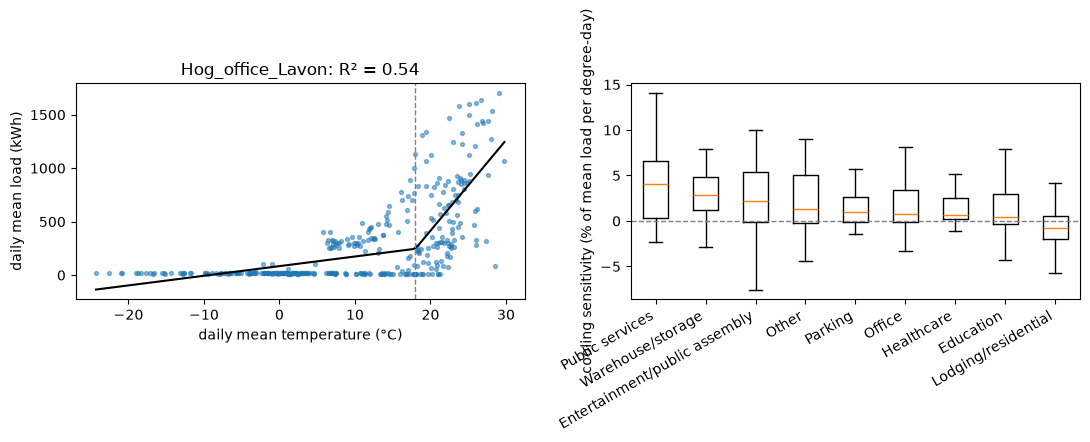

In [9]:
BASE = 18.0     # °C: below it a building may heat, above it it may cool (a common convention)

d16 = data.loc[data.index.year == 2016, ["building", "load", "temp"]].copy()
d16["date"] = d16.index.normalize()
daily = (d16.groupby(["building", "date"], observed=True)
         .agg(load=("load", "mean"), temp=("temp", "mean"), hours=("load", "count"))
         .reset_index())
daily = daily[daily["hours"] >= 20].dropna()
daily["hdd"] = (BASE - daily["temp"]).clip(lower=0)     # heating degree-days of that day
daily["cdd"] = (daily["temp"] - BASE).clip(lower=0)     # cooling degree-days of that day

# 1) Climate indicator per site: degree-days per month (one temperature series per site)
d16["site"] = d16["building"].astype(str).str.split("_").str[0]
site_t = d16.groupby(["site", d16.index])["temp"].first().unstack(0)
dd = pd.DataFrame({
    "HDD": (BASE - site_t).clip(lower=0).resample("MS").sum().stack() / 24,
    "CDD": (site_t - BASE).clip(lower=0).resample("MS").sum().stack() / 24})
dd.index.names = ["month", "site"]
site_dd = dd.groupby("site").sum().round(0)
print("Degree-days in 2016 per site (base 18 °C):")
print(site_dd.sort_values("CDD").to_string())

# 2) Temperature sensitivity per building: daily load = a + b_heat * HDD + b_cool * CDD
rows = []
for b, g in daily.groupby("building", observed=True):
    if len(g) < 200:
        continue
    X = np.column_stack([np.ones(len(g)), g["hdd"], g["cdd"]])
    coef, *_ = np.linalg.lstsq(X, g["load"].to_numpy(), rcond=None)
    pred = X @ coef
    ss_res = np.sum((g["load"] - pred) ** 2)
    ss_tot = np.sum((g["load"] - g["load"].mean()) ** 2)
    mean_load = g["load"].mean()
    rows.append({"building": b,
                 "heat_sens_pct_per_dd": 100 * coef[1] / mean_load if (g["hdd"] > 0).sum() >= 20 else np.nan,
                 "cool_sens_pct_per_dd": 100 * coef[2] / mean_load if (g["cdd"] > 0).sum() >= 20 else np.nan,
                 "r2": 1 - ss_res / ss_tot, "days": len(g)})
sens = pd.DataFrame(rows).set_index("building")
sens = sens.join(tab[["type", "site", "wins", "improvement"]], how="left")
print(len(sens), "buildings with a fit")
print(sens[["heat_sens_pct_per_dd", "cool_sens_pct_per_dd", "r2"]].describe().round(2).to_string())

sens_by_type = sens.groupby("type").agg(
    buildings=("r2", "size"),
    median_cool_sens=("cool_sens_pct_per_dd", "median"),
    median_heat_sens=("heat_sens_pct_per_dd", "median"),
    median_r2=("r2", "median")).sort_values("median_cool_sens", ascending=False)
print(sens_by_type.round(2).to_string())

# Are strongly temperature-driven buildings harder to forecast?
sens["temp_driven"] = pd.qcut(sens["r2"], 4, labels=["R² lowest 25%", "25-50%", "50-75%", "R² highest 25%"])
print(sens.groupby("temp_driven", observed=True).agg(
    buildings=("wins", "size"), win_pct=("wins", lambda s: 100 * s.mean()),
    median_improvement_pct=("improvement", lambda s: 100 * s.median())).round(1).to_string())

site_dd.to_csv("../results/tables/derived_degree_days_2016.csv")
sens.to_csv("../results/tables/derived_temperature_sensitivity.csv")

# Figure: the most cooling-sensitive building (with a good fit), and sensitivity by type
pool = sens.dropna(subset=["cool_sens_pct_per_dd"])
pool = pool[pool["r2"] >= pool["r2"].median()]            # only buildings the formula fits well
best = pool["cool_sens_pct_per_dd"].idxmax()
g = daily[daily["building"] == best]
t_grid = np.linspace(g["temp"].min(), g["temp"].max(), 100)
X = np.column_stack([np.ones(len(g)), g["hdd"], g["cdd"]])
coef, *_ = np.linalg.lstsq(X, g["load"].to_numpy(), rcond=None)
fit_line = coef[0] + coef[1] * np.clip(BASE - t_grid, 0, None) + coef[2] * np.clip(t_grid - BASE, 0, None)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(g["temp"], g["load"], s=8, alpha=0.5)
axes[0].plot(t_grid, fit_line, color="black")
axes[0].axvline(BASE, color="grey", ls="--", lw=1)
axes[0].set_xlabel("daily mean temperature (°C)")
axes[0].set_ylabel("daily mean load (kWh)")
axes[0].set_title(f"{best}: R² = {sens.loc[best, 'r2']:.2f}")
types = sens_by_type.index
axes[1].boxplot([sens.loc[sens["type"] == t, "cool_sens_pct_per_dd"].dropna() for t in types],
                showfliers=False)
axes[1].set_xticks(range(1, len(types) + 1), types, rotation=30, ha="right")
axes[1].axhline(0, color="grey", ls="--", lw=1)
axes[1].set_ylabel("cooling sensitivity (% of mean load per degree-day)")
plt.tight_layout()
plt.savefig("../results/figures/derived_temperature_sensitivity.png", dpi=150)
plt.show()

In [10]:
meta = pd.read_csv("../data/raw/metadata.csv").set_index("building_id")
new = pd.read_csv("../results/tables/cv_unseen_sites.csv", index_col=0)
print(new.join(meta[["primaryspaceusage"]]).groupby(["site", "primaryspaceusage"])["wins"].agg(["size", "mean"]).round(2))

                                       size  mean
site    primaryspaceusage                        
Panther Education                        30  0.70
        Entertainment/public assembly     5  0.60
        Lodging/residential              27  0.15
        Office                           24  0.83
        Other                             5  0.40
        Parking                           8  0.12
        Retail                            6  0.83
